# PBI 01 — Exploratory Data Analysis

This notebook explores the three CSV files in the same folder. It reads the raw data without changing it. The label file links orders to customers. The prediction is intended for review before shipment, so feature timing matters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.read_csv("customers_base.csv", low_memory=False)
orders = pd.read_csv("orders_base.csv")
labels = pd.read_csv("labels_base.csv")

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Labels:", labels.shape)

Customers: (901312, 9)
Orders: (949889, 8)
Labels: (950318, 4)


## Dataset overview

The three tables have 901,312 customer rows, 949,889 order rows and 950,318 label rows. Each table's columns, types and summary statistics are shown below. IDs are identifiers, so they are excluded from the descriptive statistics.

In [2]:
customers.info()
display(customers.drop(columns="customer_id").describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 901312 entries, 0 to 901311
Data columns (total 9 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   country_code                      901312 non-null  str    
 1   customer_id                       901312 non-null  str    
 2   mobile_verified                   901312 non-null  str    
 3   num_orders_last_50days            901312 non-null  int64  
 4   num_cancelled_orders_last_50days  901312 non-null  int64  
 5   num_refund_orders_last_50days     901312 non-null  int64  
 6   total_payment_last_50days         901312 non-null  float64
 7   num_associated_customers          901312 non-null  int64  
 8   first_order_datetime              900600 non-null  str    
dtypes: float64(1), int64(4), str(4)
memory usage: 61.9 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,901312,7,MY,339134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mobile_verified,901312,3,True,900681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_orders_last_50days,901312.0,NaN,NaN,NaN,21.711433,26.281056,0.0,5.0,14.0,29.0,2162.0
num_cancelled_orders_last_50days,901312.0,NaN,NaN,NaN,0.264327,1.005042,0.0,0.0,0.0,0.0,259.0
num_refund_orders_last_50days,901312.0,NaN,NaN,NaN,0.23079,0.8564,0.0,0.0,0.0,0.0,107.0
total_payment_last_50days,901312.0,NaN,NaN,NaN,302.180567,425.800659,0.0,51.471977,164.582166,394.230368,42569.345127
num_associated_customers,901312.0,NaN,NaN,NaN,2.685398,6.36636,1.0,1.0,2.0,3.0,101.0
first_order_datetime,900600,896426,2019-06-13 05:37:00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
orders.info()
display(orders.drop(columns="order_id").describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 949889 entries, 0 to 949888
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   country_code       949889 non-null  str    
 1   order_id           949889 non-null  str    
 2   collect_type       949889 non-null  str    
 3   payment_method     928388 non-null  str    
 4   order_value        949889 non-null  float64
 5   num_items_ordered  949888 non-null  float64
 6   refund_value       949889 non-null  float64
 7   order_date         949889 non-null  str    
dtypes: float64(3), str(5)
memory usage: 58.0 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,949889,5,MY,360569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
collect_type,949889,3,Delivery,937730,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,928388,20,payment on Delivery,312447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_value,949889.0,NaN,NaN,NaN,6.938344,6.461997,0.0,3.209875,5.509056,8.511989,662.875105
num_items_ordered,949888.0,NaN,NaN,NaN,3.670441,5.012157,1.0,1.0,2.0,4.0,1600.0
refund_value,949889.0,NaN,NaN,NaN,2.236194,3.921423,0.0,0.0,0.93,2.9,518.0
order_date,949889,235,2022/12/03,6423,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
labels.info()
display(labels.drop(columns=["customer_id", "order_id"]).describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 950318 entries, 0 to 950317
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   country_code  950318 non-null  str  
 1   order_id      950318 non-null  str  
 2   customer_id   950318 non-null  str  
 3   is_fraud      950318 non-null  int64
dtypes: int64(1), str(3)
memory usage: 29.0 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,950318,7,MY,360586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_fraud,950318.0,NaN,NaN,NaN,0.109967,0.312849,0.0,0.0,0.0,0.0,1.0


## Missing values

The percentages use the number of rows in each table. Payment method is missing for 21,501 orders (2.264%); first order date is missing for 712 customers (0.079%); and one order has a missing item count.

In [5]:
customer_missing = pd.DataFrame({
    "count": customers.isnull().sum(),
    "percent": customers.isnull().mean() * 100
})
display(customer_missing)

,count,percent
country_code,0,0.000000
customer_id,0,0.000000
mobile_verified,0,0.000000
num_orders_last_50days,0,0.000000
num_cancelled_orders_last_50days,0,0.000000
num_refund_orders_last_50days,0,0.000000
total_payment_last_50days,0,0.000000
num_associated_customers,0,0.000000
first_order_datetime,712,0.078996


In [6]:
order_missing = pd.DataFrame({
    "count": orders.isnull().sum(),
    "percent": orders.isnull().mean() * 100
})
display(order_missing)

,count,percent
country_code,0,0.000000
order_id,0,0.000000
collect_type,0,0.000000
payment_method,21501,2.263528
order_value,0,0.000000
num_items_ordered,1,0.000105
refund_value,0,0.000000
order_date,0,0.000000


In [7]:
label_missing = pd.DataFrame({
    "count": labels.isnull().sum(),
    "percent": labels.isnull().mean() * 100
})
display(label_missing)

,count,percent
country_code,0,0.0
order_id,0,0.0
customer_id,0,0.0
is_fraud,0,0.0


## Duplicate records and identifiers

There are no exact duplicate rows. Customer IDs are unique. Orders and labels each contain three repeated order IDs across different countries; this does not mean the records are duplicates. We check the composite keys after normalizing country codes in copies.

In [8]:
print("Duplicate customer rows:", customers.duplicated().sum())
print("Duplicate order rows:", orders.duplicated().sum())
print("Duplicate label rows:", labels.duplicated().sum())
print("Repeated customer IDs:", customers["customer_id"].duplicated().sum())
print("Repeated order IDs in orders:", orders["order_id"].duplicated().sum())
print("Repeated order IDs in labels:", labels["order_id"].duplicated().sum())

Duplicate customer rows: 0
Duplicate order rows: 0


Duplicate label rows: 0
Repeated customer IDs: 0
Repeated order IDs in orders: 3
Repeated order IDs in labels: 3


In [9]:
customers_clean = customers.copy()
orders_clean = orders.copy()
labels_clean = labels.copy()

customers_clean["country_code"] = customers_clean["country_code"].str.strip().str.upper()
orders_clean["country_code"] = orders_clean["country_code"].str.strip().str.upper()
labels_clean["country_code"] = labels_clean["country_code"].str.strip().str.upper()

customer_key = ["country_code", "customer_id"]
order_key = ["country_code", "order_id"]
print("Missing customer keys:", customers_clean[customer_key].isnull().any(axis=1).sum())
print("Missing order keys:", orders_clean[order_key].isnull().any(axis=1).sum())
print("Missing label order keys:", labels_clean[order_key].isnull().any(axis=1).sum())
print("Missing label customer keys:", labels_clean[customer_key].isnull().any(axis=1).sum())
print("Repeated customer composite keys:", customers_clean.duplicated(customer_key).sum())
print("Repeated order composite keys:", orders_clean.duplicated(order_key).sum())
print("Repeated label order composite keys:", labels_clean.duplicated(order_key).sum())

Missing customer keys: 0
Missing order keys: 0
Missing label order keys: 0
Missing label customer keys: 0
Repeated customer composite keys: 0
Repeated order composite keys: 0


Repeated label order composite keys: 0


## Inconsistent values and data quality

Country codes and collection types contain case variations. Mobile verification includes `yes` as well as `True` and `False`; its meaning should be confirmed before mapping it. The tables below show the original values.

In [10]:
print("Customer country codes")
display(customers["country_code"].value_counts(dropna=False))
print("Order country codes")
display(orders["country_code"].value_counts(dropna=False))
print("Label country codes")
display(labels["country_code"].value_counts(dropna=False))

Customer country codes


country_code
MY    339134
PH    289358
PK    151877
TH     72509
BD     48044
pk       225
my       165
Name: count, dtype: int64

Order country codes


country_code
MY    360569
PH    281211
PK    184822
TH     63727
BD     59560
Name: count, dtype: int64

Label country codes


country_code
MY    360586
PH    281239
PK    184840
TH     63788
BD     59564
ph       180
my       121
Name: count, dtype: int64

In [11]:
print("Mobile verification")
display(customers["mobile_verified"].astype("string").value_counts(dropna=False))
print("Collection type")
display(orders["collect_type"].value_counts(dropna=False))
print("Payment method")
display(orders["payment_method"].value_counts(dropna=False))

Mobile verification


mobile_verified
True     900681
False       466
yes         165
Name: count, dtype: Int64

Collection type


collect_type
Delivery    937730
pickup       12074
delivery        85
Name: count, dtype: int64

Payment method


payment_method
payment on Delivery       312447
cybersource               135418
online banking            124880
credit card               114242
antfinancial gcash        102657
generic creditcard         72319
balance                    25936
NaN                        21501
antfinancial bkash         17889
antfinancial truemoney      9294
boost wallet                6088
jazzcash wallet             2509
invoice                     1963
adyen hpp molpay             837
no payment                   670
cybersource applepay         584
paypal                       367
on Delivery                  160
Online Banking               103
payment on delivery           20
xendit directdebit             5
Name: count, dtype: int64

Dates are parsed only for checking: missing dates and invalid nonmissing dates are counted separately. Neither date column contains invalid nonmissing values. Refunds exceed the order value in 199,687 orders; this needs investigation, since adjustments or other business rules may explain it.

In [12]:
first_date = pd.to_datetime(customers["first_order_datetime"], errors="coerce", format="mixed")
order_date = pd.to_datetime(orders["order_date"], errors="coerce", format="mixed")

print("Invalid nonmissing customer dates:", (customers["first_order_datetime"].notna() & first_date.isna()).sum())
print("Customer date range:", first_date.min(), "to", first_date.max())
print("Invalid nonmissing order dates:", (orders["order_date"].notna() & order_date.isna()).sum())
print("Order date range:", order_date.min(), "to", order_date.max())

Invalid nonmissing customer dates: 0
Customer date range: 2012-03-25 12:53:43 to 2023-05-10 20:59:37
Invalid nonmissing order dates: 0
Order date range: 2022-11-12 00:00:00 to 2023-05-11 00:00:00


In [13]:
print("Negative customer values")
display((customers.select_dtypes(include="number") < 0).sum())
print("Negative order values")
display((orders.select_dtypes(include="number") < 0).sum())
print("Refund exceeds order value:", (orders["refund_value"] > orders["order_value"]).sum())
print("Cancellations exceed orders:", (customers["num_cancelled_orders_last_50days"] > customers["num_orders_last_50days"]).sum())
print("Refunded orders exceed orders:", (customers["num_refund_orders_last_50days"] > customers["num_orders_last_50days"]).sum())

Negative customer values


num_orders_last_50days              0
num_cancelled_orders_last_50days    0
num_refund_orders_last_50days       0
total_payment_last_50days           0
num_associated_customers            0
dtype: int64

Negative order values


order_value          0
num_items_ordered    0
refund_value         0
dtype: int64

Refund exceeds order value: 199687
Cancellations exceed orders: 0
Refunded orders exceed orders: 0


## Relationships and join checks

`country_code` plus `order_id` is the order key; `country_code` plus `customer_id` is the customer key. These checks reject missing and duplicate keys before merging. `validate` prevents accidental many-to-many joins. Outer joins show unmatched records on both sides; customers without labels may simply have no orders in this extract.

In [14]:
assert not customers_clean[customer_key].isnull().any().any()
assert not orders_clean[order_key].isnull().any().any()
assert not labels_clean[order_key].isnull().any().any()
assert not labels_clean[customer_key].isnull().any().any()
assert not customers_clean.duplicated(customer_key).any()
assert not orders_clean.duplicated(order_key).any()
assert not labels_clean.duplicated(order_key).any()

In [15]:
order_links = labels_clean.merge(
    orders_clean, on=order_key, how="outer", indicator=True, validate="one_to_one"
)
print("Labels and orders")
display(order_links["_merge"].value_counts())

Labels and orders


_merge
both          949874
left_only        444
right_only        15
Name: count, dtype: int64

In [16]:
customer_links = labels_clean.merge(
    customers_clean, on=customer_key, how="outer", indicator=True, validate="many_to_one"
)
print("Labels and customers")
display(customer_links["_merge"].value_counts())

Labels and customers


_merge
both          950304
right_only    279054
left_only         14
Name: count, dtype: int64

The order join finds 949,874 matches, 444 labels without orders and 15 orders without labels. The customer join finds 14 label rows without customers and 279,054 customers without label records. The table below compares country codes only for unambiguous IDs; repeated order IDs across countries must not be mistaken for conflicts.

In [17]:
unique_labels = labels_clean[~labels_clean["order_id"].duplicated(keep=False)]
unique_orders = orders_clean[~orders_clean["order_id"].duplicated(keep=False)]
order_countries = unique_labels[["order_id", "country_code"]].merge(
    unique_orders[["order_id", "country_code"]], on="order_id",
    suffixes=("_label", "_order"), validate="one_to_one"
)
print("Order country conflicts:", (order_countries["country_code_label"] != order_countries["country_code_order"]).sum())

Order country conflicts: 0


In [18]:
customer_countries = labels_clean[["customer_id", "country_code"]].merge(
    customers_clean[["customer_id", "country_code"]], on="customer_id",
    suffixes=("_label", "_customer"), validate="many_to_one"
)
print("Customer country conflicts:", (customer_countries["country_code_label"] != customer_countries["country_code_customer"]).sum())
print("Order IDs with different fraud labels across countries:", labels_clean.groupby("order_id")["is_fraud"].nunique().gt(1).sum())

Customer country conflicts: 0


Order IDs with different fraud labels across countries: 1


Country conflicts on unambiguous IDs are zero after normalization. One repeated order ID has different labels in different countries; it represents different composite keys, not necessarily conflicting labels.

In [19]:
joined = labels_clean.merge(
    orders_clean, on=order_key, how="left", indicator="order_match", validate="one_to_one"
)
joined = joined.merge(
    customers_clean, on=customer_key, how="left", indicator="customer_match", validate="many_to_one"
)
assert len(joined) == len(labels_clean)
print("Label rows retained:", len(joined))

Label rows retained: 950318


## Numerical distributions and outliers

The table uses all available values. Skewness shows that several counts and amounts have long right tails. The 1.5 × IQR rule flags possible outliers; for a zero IQR it flags every positive value, so flags should not automatically be removed. Histograms below show values up to the 99th percentile for readability, excluding the remaining upper tail from the charts only.

In [20]:
customer_numbers = customers.select_dtypes(include="number")
order_numbers = orders.select_dtypes(include="number")
print("Customer statistics")
display(customer_numbers.describe().T)
print("Customer skewness")
display(customer_numbers.skew())
print("Order statistics")
display(order_numbers.describe().T)
print("Order skewness")
display(order_numbers.skew())

Customer statistics


,count,mean,std,min,25%,50%,75%,max
num_orders_last_50days,901312.0,21.711433,26.281056,0.0,5.000000,14.000000,29.000000,2162.000000
num_cancelled_orders_last_50days,901312.0,0.264327,1.005042,0.0,0.000000,0.000000,0.000000,259.000000
num_refund_orders_last_50days,901312.0,0.230790,0.856400,0.0,0.000000,0.000000,0.000000,107.000000
total_payment_last_50days,901312.0,302.180567,425.800659,0.0,51.471977,164.582166,394.230368,42569.345127
num_associated_customers,901312.0,2.685398,6.366360,1.0,1.000000,2.000000,3.000000,101.000000


Customer skewness


num_orders_last_50days               5.419459
num_cancelled_orders_last_50days    54.998623
num_refund_orders_last_50days       17.515436
total_payment_last_50days            8.676179
num_associated_customers            12.478703
dtype: float64

Order statistics


,count,mean,std,min,25%,50%,75%,max
order_value,949889.0,6.938344,6.461997,0.0,3.209875,5.509056,8.511989,662.875105
num_items_ordered,949888.0,3.670441,5.012157,1.0,1.000000,2.000000,4.000000,1600.000000
refund_value,949889.0,2.236194,3.921423,0.0,0.000000,0.930000,2.900000,518.000000


Order skewness


order_value           6.620409
num_items_ordered    41.042020
refund_value          8.409762
dtype: float64

In [21]:
customer_q1 = customer_numbers.quantile(0.25)
customer_q3 = customer_numbers.quantile(0.75)
customer_iqr = customer_q3 - customer_q1
customer_outliers = (customer_numbers.lt(customer_q1 - 1.5 * customer_iqr) |
                     customer_numbers.gt(customer_q3 + 1.5 * customer_iqr))
display(pd.DataFrame({"IQR": customer_iqr, "possible outliers": customer_outliers.sum()}))

,IQR,possible outliers
num_orders_last_50days,24.000000,53579
num_cancelled_orders_last_50days,0.000000,151945
num_refund_orders_last_50days,0.000000,128372
total_payment_last_50days,342.758391,63144
num_associated_customers,2.000000,39178


In [22]:
order_q1 = order_numbers.quantile(0.25)
order_q3 = order_numbers.quantile(0.75)
order_iqr = order_q3 - order_q1
order_outliers = (order_numbers.lt(order_q1 - 1.5 * order_iqr) |
                  order_numbers.gt(order_q3 + 1.5 * order_iqr))
display(pd.DataFrame({"IQR": order_iqr, "possible outliers": order_outliers.sum()}))

,IQR,possible outliers
order_value,5.302114,56798
num_items_ordered,3.000000,69852
refund_value,2.900000,71069


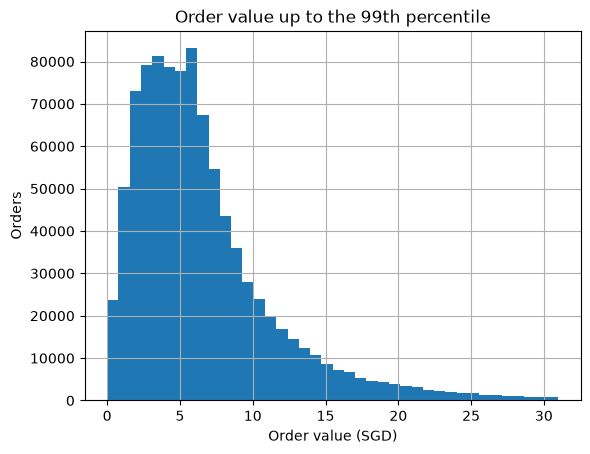

In [23]:
orders["order_value"].loc[orders["order_value"] <= orders["order_value"].quantile(0.99)].hist(bins=40)
plt.title("Order value up to the 99th percentile")
plt.xlabel("Order value (SGD)")
plt.ylabel("Orders")
plt.show()

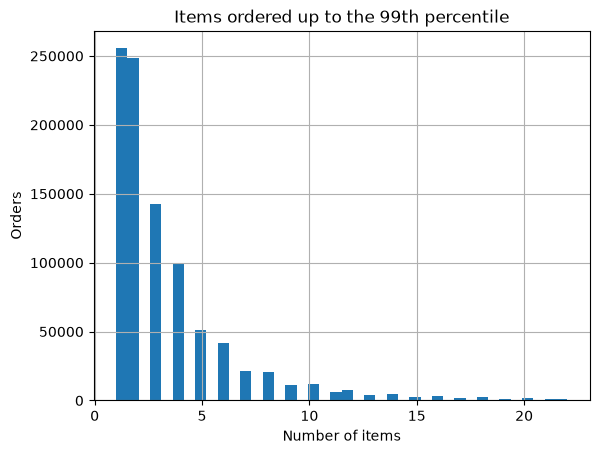

In [24]:
orders["num_items_ordered"].loc[orders["num_items_ordered"] <= orders["num_items_ordered"].quantile(0.99)].hist(bins=40)
plt.title("Items ordered up to the 99th percentile")
plt.xlabel("Number of items")
plt.ylabel("Orders")
plt.show()

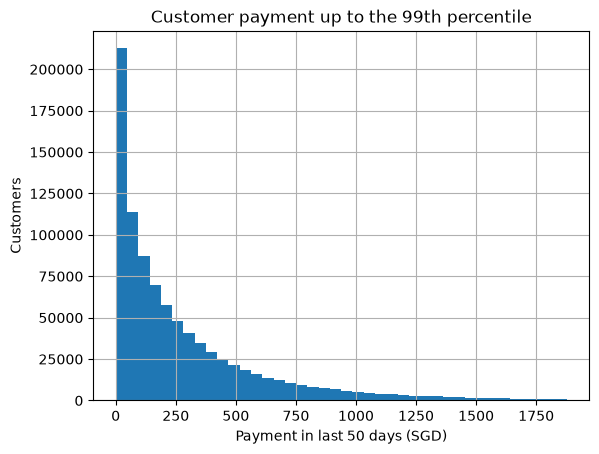

In [25]:
customers["total_payment_last_50days"].loc[customers["total_payment_last_50days"] <= customers["total_payment_last_50days"].quantile(0.99)].hist(bins=40)
plt.title("Customer payment up to the 99th percentile")
plt.xlabel("Payment in last 50 days (SGD)")
plt.ylabel("Customers")
plt.show()

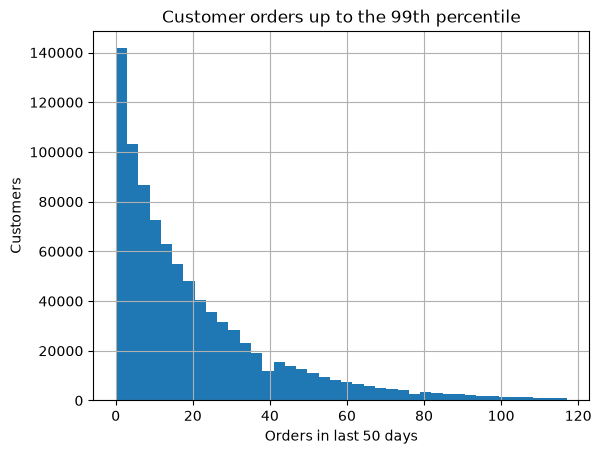

In [26]:
customers["num_orders_last_50days"].loc[customers["num_orders_last_50days"] <= customers["num_orders_last_50days"].quantile(0.99)].hist(bins=40)
plt.title("Customer orders up to the 99th percentile")
plt.xlabel("Orders in last 50 days")
plt.ylabel("Customers")
plt.show()

## Fraud distribution and patterns

There are 104,504 fraud labels (11.0%) and 845,814 non-fraud labels (89.0%). The following patterns use only matched labeled orders, with group counts shown in tables. They are associations, not proof of cause. Refund and customer history are not used in the charts because their availability at prediction time is uncertain.

,count,percent
is_fraud,,
0,845814,89.00326
1,104504,10.99674


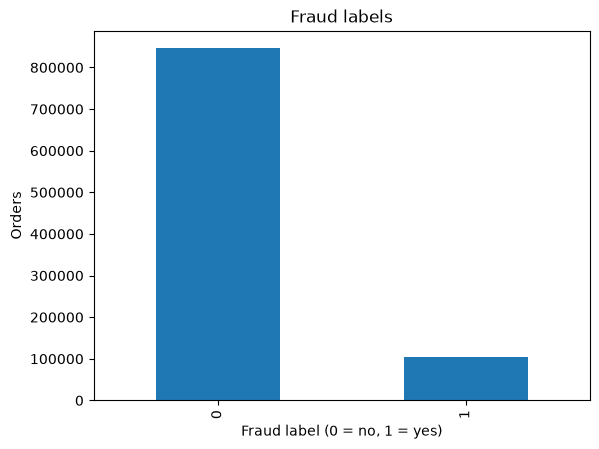

In [27]:
fraud_counts = labels["is_fraud"].value_counts(dropna=False).sort_index()
fraud_percent = labels["is_fraud"].value_counts(dropna=False, normalize=True).sort_index() * 100
display(pd.DataFrame({"count": fraud_counts, "percent": fraud_percent}))
fraud_counts.plot.bar()
plt.title("Fraud labels")
plt.xlabel("Fraud label (0 = no, 1 = yes)")
plt.ylabel("Orders")
plt.show()

Matched labeled orders: 949874


,orders,fraud_rate
collection,,
delivery,937800,0.107637
pickup,12074,0.288223


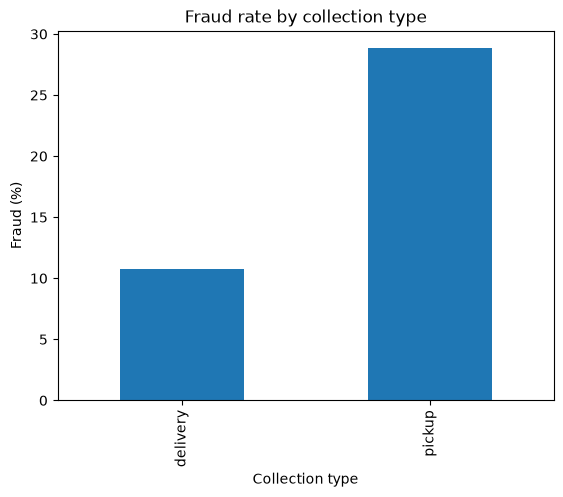

In [28]:
matched = joined[(joined["order_match"] == "both") & (joined["is_fraud"].isin([0, 1]))].copy()
print("Matched labeled orders:", len(matched))
matched["collection"] = matched["collect_type"].str.strip().str.lower().fillna("missing")
collection_rates = matched.groupby("collection")["is_fraud"].agg(["size", "mean"])
collection_rates.columns = ["orders", "fraud_rate"]
display(collection_rates)
(collection_rates["fraud_rate"] * 100).plot.bar()
plt.title("Fraud rate by collection type")
plt.xlabel("Collection type")
plt.ylabel("Fraud (%)")
plt.show()

,orders,fraud_rate
value_band,,
"(-0.001, 2.737]",189979,0.138447
"(2.737, 4.58]",189971,0.106758
"(4.58, 6.447]",189974,0.091312
"(6.447, 9.584]",189975,0.090296
"(9.584, 662.875]",189975,0.122848


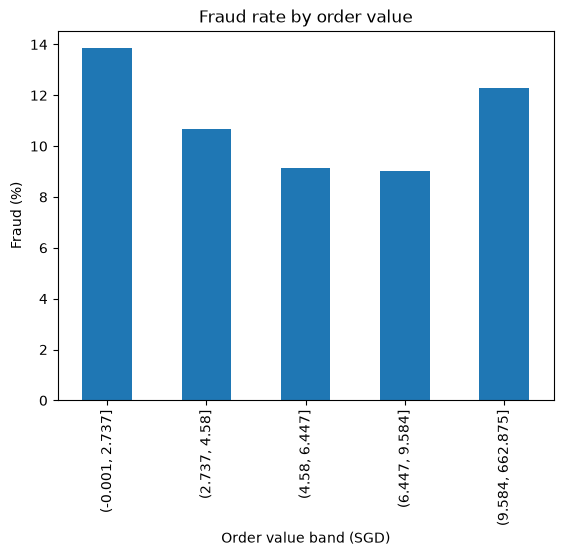

In [29]:
matched["value_band"] = pd.qcut(matched["order_value"], 5, duplicates="drop")
value_rates = matched.groupby("value_band", observed=True)["is_fraud"].agg(["size", "mean"])
value_rates.columns = ["orders", "fraud_rate"]
display(value_rates)
(value_rates["fraud_rate"] * 100).plot.bar()
plt.title("Fraud rate by order value")
plt.xlabel("Order value band (SGD)")
plt.ylabel("Fraud (%)")
plt.show()

## Data quality recommendations and limitations

- **PBI 02:** Standardize country and collection-type case on copies. Confirm whether `yes` means true. Investigate missing values, unmatched keys and refund amounts greater than order values. Keep missing indicators and do not invent missing labels. Do not deduplicate using order ID alone.
- **PBI 03:** Confirm which fields exist at the pre-shipment prediction time. Exclude the fraud label, refund value, refund-related history and snapshot aggregates that may contain later information until their timing is verified. Build customer history using only information available before each order.
- Consider log transformations for skewed nonnegative values, robust scaling and categorical encoding. Fit imputation, encoding, scaling and any resampling on training data only. Investigate outliers instead of automatically deleting them.
- Fraud is the minority class. Report precision and recall as well as accuracy, and consider class weighting or training-only resampling. Use time-aware validation and check for repeated customers across splits.

The quality register and findings summary in `reports/` give the affected counts and recommendations. These findings describe the historical files and are not evidence of causation.